# Projeto Scraper & Crawler — Books to Scrape

| Nome | RA |
|---|---|
| Gabriela Viana Cunha | 2411550012 |
| Kaique Alexandre Souza Kubota | 2411550841 |
| Maria Vitória Alvim Nardotto | 2411550024 |

**Site:** [books.toscrape.com](https://books.toscrape.com), uma livraria fictícia feita para praticar web scraping
(1.000 livros em 50 páginas).

**Objetivo:** com Selenium (navegação) e BeautifulSoup (extração), percorrer as páginas do catálogo clicando em
*next*, abrir a página de cada livro, tratar os dados com pandas e analisá-los com gráficos.

1. Setup
2. Coleta do catálogo (paginação)
3. Crawling das páginas dos livros
4. Tratamento dos dados
5. Visualizações
6. Conclusões

## 1. Setup

In [1]:
%pip install selenium beautifulsoup4 pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\Kaique Kubota\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.support.ui import WebDriverWait

O Selenium (versão 4.6+) baixa sozinho o chromedriver compatível com o Chrome instalado, então não é preciso
informar o caminho do driver. `HEADLESS = False` roda o navegador sem abrir a janela.

In [3]:
HEADLESS = False
PAGES = 10
BASE_URL = 'https://books.toscrape.com/catalogue/'

def web_driver():
    options = webdriver.ChromeOptions()
    if HEADLESS:
        options.add_argument('--headless=new')
    return webdriver.Chrome(options=options)

def get_soup(driver):
    return BeautifulSoup(driver.page_source, 'html.parser')

## 2. Coleta do catálogo (paginação)

Cada página do catálogo tem 20 livros. O BeautifulSoup extrai título, link, preço e avaliação (estrelas) de cada um;
depois o Selenium clica no botão *next* e espera o indicador "Page X of 50" mudar antes de ler a próxima página.

In [4]:
driver = web_driver()
driver.get(BASE_URL + 'page-1.html')

books = []
for page in range(1, PAGES + 1):
    soup = get_soup(driver)
    for article in soup.select('article.product_pod'):
        books.append({
            'titulo': article.h3.a['title'],
            'link': BASE_URL + article.h3.a['href'],
            'preco': article.select_one('.price_color').text,
            'avaliacao': article.select_one('.star-rating')['class'][1],
        })
    if page < PAGES:
        driver.find_element(By.CSS_SELECTOR, 'li.next a').click()
        WebDriverWait(driver, 10).until(
            EC.text_to_be_present_in_element((By.CSS_SELECTOR, 'li.current'), f'Page {page + 1} of'))

len(books)

200

In [5]:
books[0]

{'titulo': 'A Light in the Attic',
 'link': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html',
 'preco': '£51.77',
 'avaliacao': 'Three'}

## 3. Crawling das páginas dos livros

O Selenium abre o link de cada livro; da página de detalhe extraímos a categoria (no caminho *Home > Books > Categoria*),
o estoque disponível e o código UPC (identificador único do livro).

In [6]:
for book in books:
    driver.get(book['link'])
    soup = get_soup(driver)
    info = {row.th.text: row.td.text for row in soup.select('table.table tr')}
    book['categoria'] = soup.select('ul.breadcrumb a')[-1].text
    book['estoque'] = info['Availability']
    book['upc'] = info['UPC']

driver.quit()
books[0]

{'titulo': 'A Light in the Attic',
 'link': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html',
 'preco': '£51.77',
 'avaliacao': 'Three',
 'categoria': 'Poetry',
 'estoque': 'In stock (22 available)',
 'upc': 'a897fe39b1053632'}

## 4. Tratamento dos dados

- remoção de duplicados (pelo UPC) e de linhas incompletas;
- preço `£51.77` → `51.77` (float);
- avaliação `Three` → `3` (int);
- estoque `In stock (22 available)` → `22` (int);
- as categorias genéricas do site (`Default` e `Add a comment`) viram `Sem categoria`.

In [7]:
RATINGS = {'One': 1, 'Two': 2, 'Three': 3, 'Four': 4, 'Five': 5}

df = pd.DataFrame(books).drop_duplicates('upc').dropna()
df['titulo'] = df['titulo'].str.strip()
df['preco'] = df['preco'].str.replace(r'[^\d.]', '', regex=True).astype(float)
df['avaliacao'] = df['avaliacao'].map(RATINGS)
df['estoque'] = df['estoque'].str.extract(r'(\d+)')[0].astype(int)
df['categoria'] = df['categoria'].replace({'Default': 'Sem categoria', 'Add a comment': 'Sem categoria'})

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   titulo     200 non-null    object 
 1   link       200 non-null    object 
 2   preco      200 non-null    float64
 3   avaliacao  200 non-null    int64  
 4   categoria  200 non-null    object 
 5   estoque    200 non-null    int64  
 6   upc        200 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 11.1+ KB


In [8]:
df.head()

,titulo,link,preco,avaliacao,categoria,estoque,upc
0,A Light in the Attic,https://books.toscrape.com/catalogue/a-light-i...,51.77,3,Poetry,22,a897fe39b1053632
1,Tipping the Velvet,https://books.toscrape.com/catalogue/tipping-t...,53.74,1,Historical Fiction,20,90fa61229261140a
2,Soumission,https://books.toscrape.com/catalogue/soumissio...,50.10,1,Fiction,20,6957f44c3847a760
3,Sharp Objects,https://books.toscrape.com/catalogue/sharp-obj...,47.82,4,Mystery,20,e00eb4fd7b871a48
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue/sapiens-a...,54.23,5,History,20,4165285e1663650f


In [9]:
df.describe()

,preco,avaliacao,estoque
count,200.000000,200.000000,200.000000
mean,34.796250,2.865000,16.230000
std,14.119272,1.451658,1.448305
min,10.160000,1.000000,15.000000
25%,21.990000,2.000000,15.000000
50%,35.640000,3.000000,16.000000
75%,46.110000,4.000000,16.000000
max,59.640000,5.000000,22.000000


In [10]:
df.to_csv('livros.csv', index=False)

## 5. Visualizações

In [11]:
categories = df.groupby('categoria').agg(
    livros=('titulo', 'count'),
    preco_medio=('preco', 'mean'),
    avaliacao_media=('avaliacao', 'mean'),
    estoque_total=('estoque', 'sum'),
).sort_values('livros', ascending=False)

categories.head(10).round(2)

,livros,preco_medio,avaliacao_media,estoque_total
categoria,,,,
Sem categoria,38,32.88,2.74,606
Sequential Art,23,33.52,2.87,369
Nonfiction,20,32.69,2.85,321
Young Adult,10,31.75,3.40,162
Fantasy,10,35.96,2.40,157
Food and Drink,9,36.98,2.44,143
Fiction,9,43.05,3.89,145
Poetry,9,34.32,2.56,159
Romance,9,29.30,2.89,146


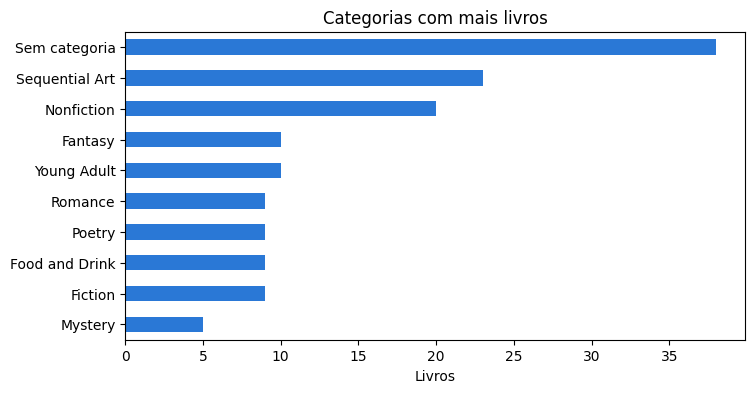

In [12]:
categories['livros'].head(10).sort_values().plot.barh(color='#2a78d6', figsize=(8, 4))
plt.title('Categorias com mais livros')
plt.xlabel('Livros')
plt.ylabel('')
plt.show()

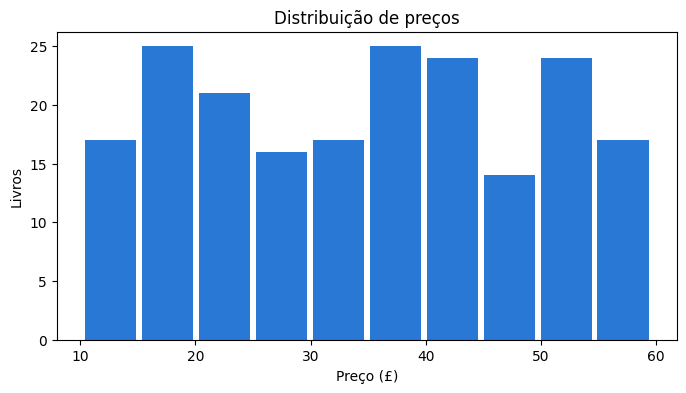

In [13]:
df['preco'].plot.hist(bins=10, color='#2a78d6', rwidth=0.9, figsize=(8, 4))
plt.title('Distribuição de preços')
plt.xlabel('Preço (£)')
plt.ylabel('Livros')
plt.show()

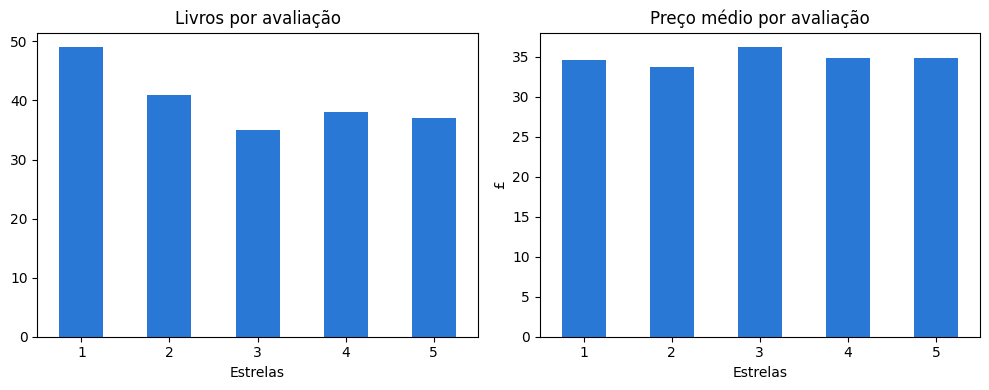

In [14]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
df['avaliacao'].value_counts().sort_index().plot.bar(ax=left, color='#2a78d6', rot=0)
left.set_title('Livros por avaliação')
left.set_xlabel('Estrelas')
df.groupby('avaliacao')['preco'].mean().plot.bar(ax=right, color='#2a78d6', rot=0)
right.set_title('Preço médio por avaliação')
right.set_xlabel('Estrelas')
right.set_ylabel('£')
plt.tight_layout()
plt.show()

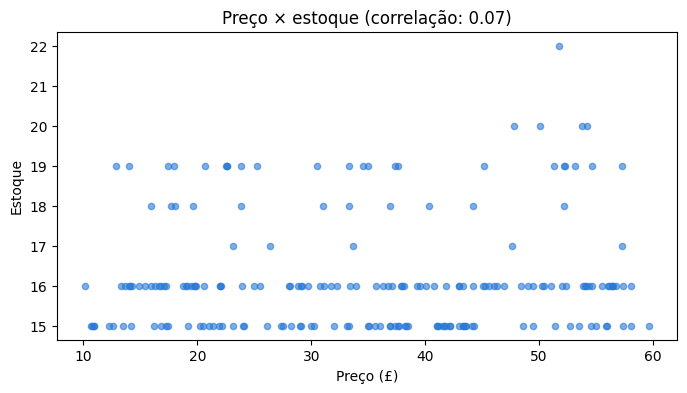

In [15]:
df.plot.scatter(x='preco', y='estoque', color='#2a78d6', alpha=0.6, figsize=(8, 4))
plt.title(f'Preço × estoque (correlação: {df["preco"].corr(df["estoque"]):.2f})')
plt.xlabel('Preço (£)')
plt.ylabel('Estoque')
plt.show()

In [16]:
df.nlargest(5, 'preco')[['titulo', 'categoria', 'preco', 'avaliacao']]

,titulo,categoria,preco,avaliacao
133,Thomas Jefferson and the Tripoli Pirates: The ...,History,59.64,1
68,The Death of Humanity: and the Case for Life,Philosophy,58.11,4
135,The White Cat and the Monk: A Retelling of the...,Childrens,58.08,4
100,Immunity: How Elie Metchnikoff Changed the Cou...,Science,57.36,5
186,I Had a Nice Time And Other Lies...: How to fi...,Womens Fiction,57.36,4


## 6. Conclusões

- **Coleta:** 10 páginas do catálogo percorridas com o botão *next*, 200 livros coletados e 200 páginas de detalhe
  visitadas, sem duplicados nem valores faltantes após o tratamento.
- **Categorias:** 35 categorias; *Sequential Art* (23 livros) e *Nonfiction* (20) são as maiores. 38 livros estão em
  categorias genéricas do site (*Default* / *Add a comment*), agrupadas como *Sem categoria*.
- **Preços:** de £10,16 a £59,64, com média de £34,80, espalhados de forma quase uniforme por toda a faixa.
- **Avaliações:** 1 estrela é a nota mais comum (49 livros). O preço não acompanha a nota: o preço médio por nota fica
  entre £33,74 e £36,19 e a correlação entre preço e avaliação é praticamente zero (0,02).
- **Destaque:** entre as categorias com pelo menos 5 livros, *Fiction* tem a melhor nota média (3,9 estrelas) e também
  um dos maiores preços médios (£43,05).
- **Estoque:** entre 15 e 22 unidades por livro, 78% deles com 15 ou 16; o estoque também não depende do preço (correlação de 0,07).

Como o site é fictício e seus dados foram gerados para prática, a ausência de relação entre preço, avaliação e estoque
é esperada: o valor do projeto está no processo de coleta (paginação + crawling), tratamento e análise.